# Estimating Insurance Losses Using Monte Carlo Simulation

## Project Overview

This project applies statistical analysis, Monte Carlo simulation, and multiple linear regression to estimate annual insurance losses using a real-world medical insurance dataset from Kaggle.

The project demonstrates:

- Exploratory Data Analysis (EDA)
- Descriptive Statistics
- Correlation Analysis
- Hypothesis Testing
- Multiple Linear Regression
- Monte Carlo Simulation
- Value at Risk (VaR)
- Conditional Value at Risk (CVaR)

**Tools Used**

- Python
- NumPy
- Pandas
- Matplotlib
- SciPy
- Scikit-learn

# Dataset

The dataset contains information about 1,338 insurance policyholders.

Variables include:

- Age
- Sex
- BMI
- Number of Children
- Smoking Status
- Region
- Insurance Charges

Target Variable:

**charges**

Source:
Medical Cost Personal Dataset (Kaggle)

# Exploratory Data Analysis

The objective of the exploratory data analysis is to understand the characteristics of the dataset before applying statistical and simulation techniques.

The analysis includes:

- Missing value analysis
- Descriptive statistics
- Distribution of insurance charges
- Age vs Charges
- Charges by Smoking Status
- Correlation Analysis

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)

NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3


In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display plots inside Colab
%matplotlib inline

In [74]:
import os

print(os.listdir())

['.config', 'insurance.csv', 'sample_data']


In [75]:
import os
print(os.listdir())

['.config', 'insurance.csv', 'sample_data']


In [76]:
import pandas as pd

df = pd.read_csv("insurance.csv")

In [77]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [79]:
df.shape

(1338, 7)

In [80]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [81]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


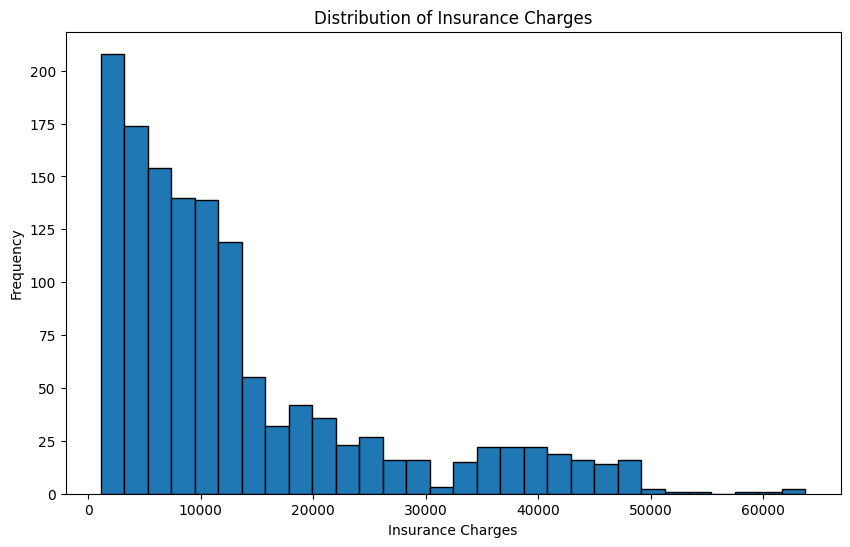

In [84]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.hist(df["charges"], bins=30, edgecolor="black")

plt.title("Distribution of Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Frequency")

plt.show()

In [82]:
from scipy.stats import skew, kurtosis

print("Skewness :", skew(df["charges"]))
print("Kurtosis:", kurtosis(df["charges"]))

Skewness : 1.5141797118745743
Kurtosis: 1.595821363956751


In [85]:
# Number of customers in the original dataset
n = len(df)

# Draw one bootstrap sample (with replacement)
bootstrap_sample = df["charges"].sample(
    n=n,
    replace=True,
    random_state=42
)

# Display the first 10 sampled claim amounts
bootstrap_sample.head(10)

,charges
1126,10214.63600
860,46113.51100
1294,11931.12525
1130,8582.30230
1095,4561.18850
1044,11394.06555
121,1705.62450
466,13224.69300
1238,6985.50695
330,48517.56315


In [83]:
# Total insurance loss for one simulated year
total_loss = bootstrap_sample.sum()

print(f"Total simulated annual loss: ${total_loss:,.2f}")

Total simulated annual loss: $18,189,520.38


In [86]:
# Number of Monte Carlo simulations
num_simulations = 10000

# Store total loss from each simulation
annual_losses = []

# Number of customers
n = len(df)

# Monte Carlo Simulation
for i in range(num_simulations):

    # Bootstrap sample
    sample = df["charges"].sample(
        n=n,
        replace=True
    )

    # Total annual loss
    total_loss = sample.sum()

    # Save result
    annual_losses.append(total_loss)

print("Simulation completed!")

print("Number of simulations:", len(annual_losses))

Simulation completed!
Number of simulations: 10000


In [87]:
annual_losses[:10]

[np.float64(17331692.269858),
 np.float64(17721951.313388),
 np.float64(17350808.36765),
 np.float64(18418839.088749),
 np.float64(17449575.865718998),
 np.float64(18248338.708159998),
 np.float64(17312162.11089),
 np.float64(17892637.678989),
 np.float64(17768634.09197),
 np.float64(17414140.945499998)]

In [88]:
print("Number of simulations:", len(annual_losses))

Number of simulations: 10000


In [89]:
annual_losses[:10]

[np.float64(17331692.269858),
 np.float64(17721951.313388),
 np.float64(17350808.36765),
 np.float64(18418839.088749),
 np.float64(17449575.865718998),
 np.float64(18248338.708159998),
 np.float64(17312162.11089),
 np.float64(17892637.678989),
 np.float64(17768634.09197),
 np.float64(17414140.945499998)]

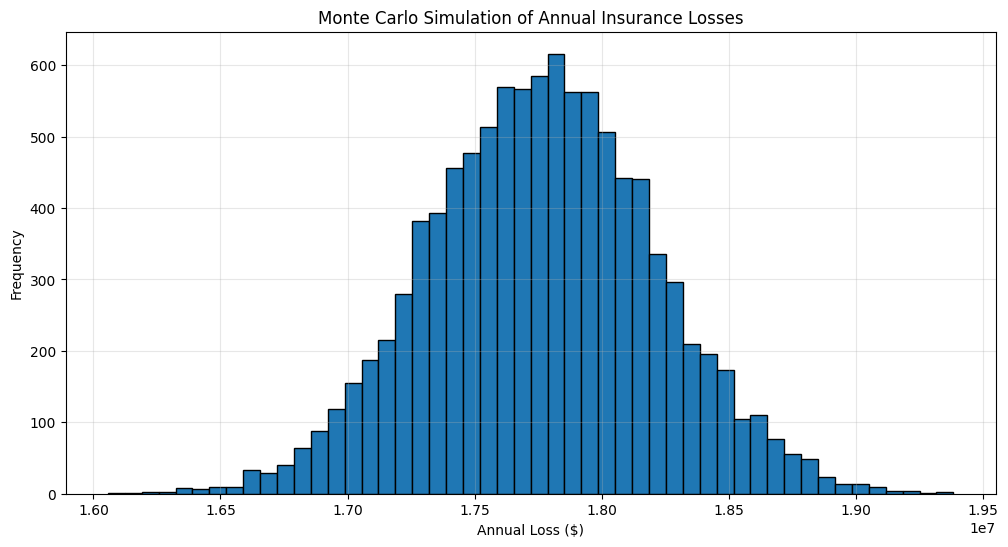

In [90]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.hist(annual_losses,
         bins=50,
         edgecolor="black")

plt.title("Monte Carlo Simulation of Annual Insurance Losses")

plt.xlabel("Annual Loss ($)")

plt.ylabel("Frequency")

plt.grid(alpha=0.3)

plt.show()

In [91]:
import numpy as np

# Convert list to NumPy array
annual_losses = np.array(annual_losses)

# Basic statistics
mean_loss = np.mean(annual_losses)
median_loss = np.median(annual_losses)
std_loss = np.std(annual_losses)

# Value at Risk (95%)
var95 = np.percentile(annual_losses, 95)

# Conditional Value at Risk (Expected Shortfall)
cvar95 = annual_losses[annual_losses >= var95].mean()

print(f"Mean Annual Loss: ${mean_loss:,.2f}")
print(f"Median Annual Loss: ${median_loss:,.2f}")
print(f"Standard Deviation: ${std_loss:,.2f}")
print(f"95% Value at Risk (VaR): ${var95:,.2f}")
print(f"95% Conditional VaR (CVaR): ${cvar95:,.2f}")

Mean Annual Loss: $17,762,925.73
Median Annual Loss: $17,763,865.29
Standard Deviation: $447,522.43
95% Value at Risk (VaR): $18,504,068.58
95% Conditional VaR (CVaR): $18,696,094.74


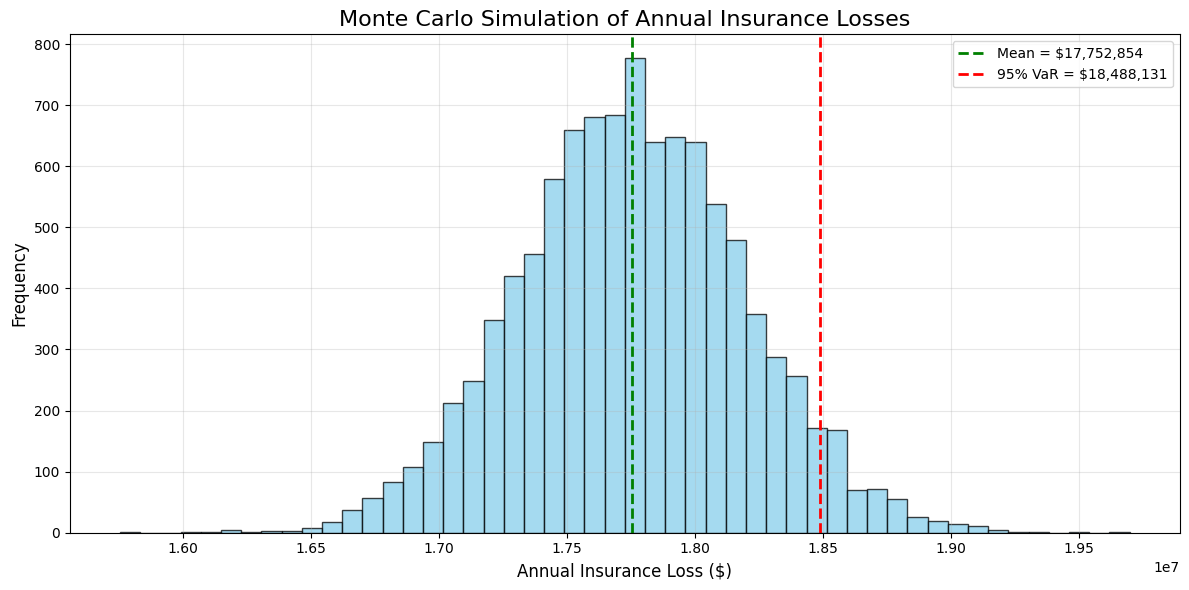

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

# Histogram
plt.hist(
    annual_losses,
    bins=50,
    edgecolor='black',
    alpha=0.75,
    color='skyblue'
)

# Mean Line
plt.axvline(
    mean_loss,
    color='green',
    linestyle='--',
    linewidth=2,
    label=f"Mean = ${mean_loss:,.0f}"
)

# VaR Line
plt.axvline(
    var95,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f"95% VaR = ${var95:,.0f}"
)

plt.title("Monte Carlo Simulation of Annual Insurance Losses", fontsize=16)
plt.xlabel("Annual Insurance Loss ($)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [59]:
# Probability that annual losses exceed the VaR threshold
prob_exceed_var = np.mean(annual_losses > var95)

print(f"Probability of exceeding VaR: {prob_exceed_var:.2%}")

Probability of exceeding VaR: 5.00%


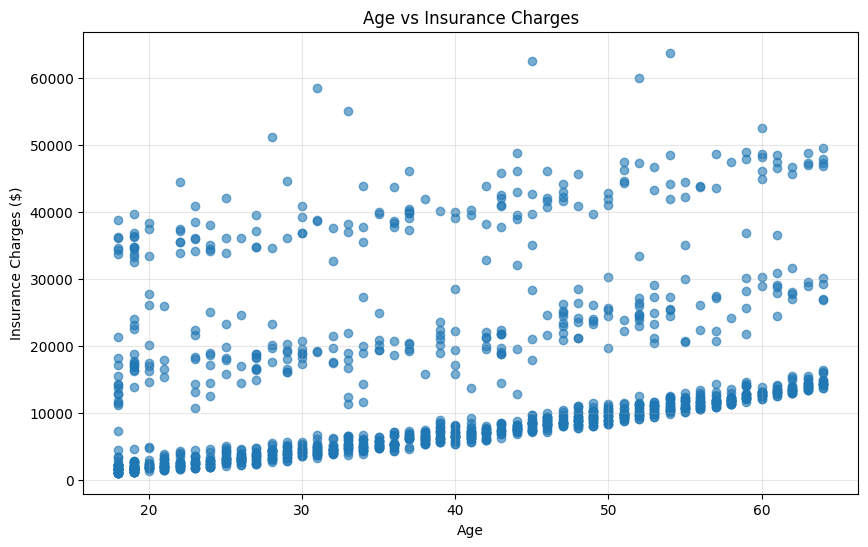

In [60]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["age"],
    df["charges"],
    alpha=0.6
)

plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges ($)")

plt.grid(alpha=0.3)

plt.show()

<Figure size 800x600 with 0 Axes>

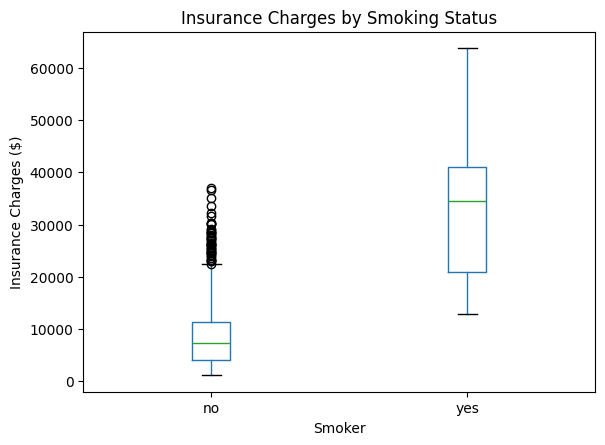

In [61]:
plt.figure(figsize=(8,6))

df.boxplot(
    column="charges",
    by="smoker",
    grid=False
)

plt.title("Insurance Charges by Smoking Status")
plt.suptitle("")  # Removes the default title
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges ($)")

plt.show()

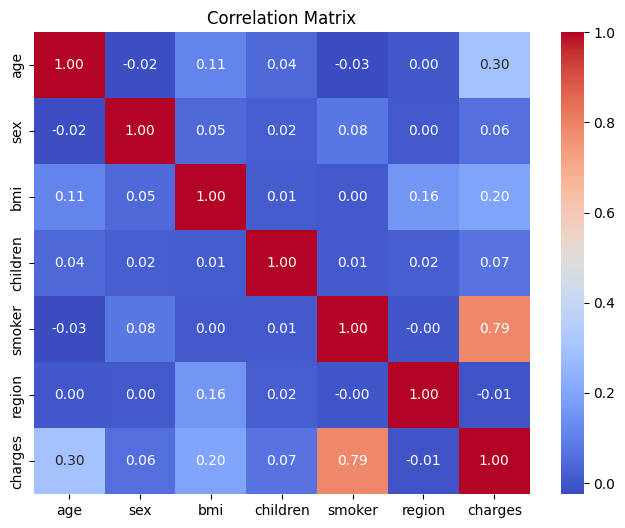

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a copy for correlation analysis
corr_df = df.copy()

# Convert categorical columns to numbers
corr_df["sex"] = corr_df["sex"].map({"female": 0, "male": 1})
corr_df["smoker"] = corr_df["smoker"].map({"no": 0, "yes": 1})
corr_df["region"] = corr_df["region"].astype("category").cat.codes

# Correlation matrix
corr = corr_df.corr(numeric_only=True)

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [63]:
# Average charges by smoker
smoker_summary = (
    df.groupby("smoker")["charges"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .round(2)
)

print(smoker_summary)

        count      mean    median       std       min       max
smoker                                                         
no       1064   8434.27   7345.41   5993.78   1121.87  36910.61
yes       274  32050.23  34456.35  11541.55  12829.46  63770.43


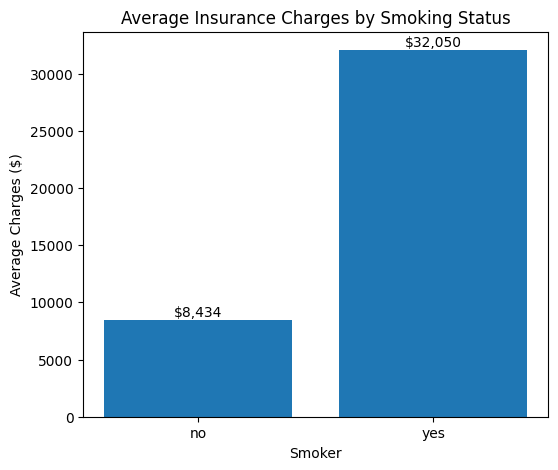

In [64]:
import matplotlib.pyplot as plt

avg_charges = df.groupby("smoker")["charges"].mean()

plt.figure(figsize=(6,5))

bars = plt.bar(avg_charges.index, avg_charges.values)

plt.title("Average Insurance Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Average Charges ($)")

# Add values above bars
for bar in bars:
    y = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        y + 300,
        f"${y:,.0f}",
        ha="center",
        fontsize=10
    )

plt.show()

In [65]:
ratio = smoker_summary.loc["yes", "mean"] / smoker_summary.loc["no", "mean"]

print(f"Smokers cost {ratio:.2f}x more than non-smokers on average.")

Smokers cost 3.80x more than non-smokers on average.


In [66]:
from scipy.stats import ttest_ind

smoker = df[df["smoker"] == "yes"]["charges"]
non_smoker = df[df["smoker"] == "no"]["charges"]

t_stat, p_value = ttest_ind(
    smoker,
    non_smoker,
    equal_var=False
)

print("T-statistic:", round(t_stat, 3))
print("P-value:", p_value)

T-statistic: 32.752
P-value: 5.88946444671698e-103


In [67]:
# One-hot encode categorical variables
df_model = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True
)

df_model.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [68]:
df_model.columns

Index(['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes',
       'region_northwest', 'region_southeast', 'region_southwest'],
      dtype='object')

In [69]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Features
X = df_model.drop("charges", axis=1)

# Target
y = df_model["charges"]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

print("Model trained successfully!")

Model trained successfully!


In [70]:
print(f"R² Score: {r2_score(y_test, y_pred):.3f}")
print(f"MAE: ${mean_absolute_error(y_test, y_pred):,.2f}")
print(f"RMSE: ${mean_squared_error(y_test, y_pred)**0.5:,.2f}")

R² Score: 0.784
MAE: $4,181.19
RMSE: $5,796.28


In [71]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

coefficients

,Feature,Coefficient
4,smoker_yes,23651.128856
7,region_southwest,-809.799354
6,region_southeast,-657.864297
2,children,425.278784
5,region_northwest,-370.677326
1,bmi,337.092552
0,age,256.975706
3,sex_male,-18.591692


In [93]:
plt.tight_layout()
plt.savefig("charges_distribution.png", dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

In [94]:
plt.tight_layout()
plt.savefig("age_vs_charges.png", dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

In [95]:
plt.tight_layout()
plt.savefig("smoker_boxplot.png", dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

In [96]:
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

In [97]:
plt.tight_layout()
plt.savefig("	monte_carlo_simulation.png", dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>